## Step 3: Building a prediction model

In [15]:
import pandas as pd

df = pd.read_csv('cleaned_dataset.csv')

In [16]:
#Split the data into X and y
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["month"] = df["Date"].dt.month

X = df.drop(["Retard moyen de tous les trains à l\'arrivée", "Date", "Service", "Gare de départ", "Gare d'arrivée"], axis=1)
y = df["Retard moyen de tous les trains à l\'arrivée"]

X.shape, y.shape

((10664, 19), (10664,))

In [17]:
from sklearn.model_selection import train_test_split
#Split the data into training and testing

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#print shape of training and testing
print("Training set shape: ", X_train.shape, y_train.shape)
print("Testing set shape: ", X_test.shape, y_test.shape)

Training set shape:  (8531, 19) (8531,)
Testing set shape:  (2133, 19) (2133,)


In [18]:
from sklearn.linear_model import LinearRegression

#Create a linear regression model

lr = LinearRegression()

In [19]:
#Model training

lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [20]:
#Predict on testing set

y_predict = lr.predict(X_test)

#y_predict are predicted values of the target variable based on the columns

In [21]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#Evaluate the performance of the model
   
r2 = r2_score(y_test, y_predict) #Variance of the target explained by the independent variables (features)  / Higher value is better
mse = mean_squared_error(y_test, y_predict) #Average squared distance between the predicted and the actual values  / Lower value is better
mae = mean_absolute_error(y_test, y_predict) #Average absolute distance between the predicted and the actual values  / Lower value is better
intercept = lr.intercept_  #Starting point of the regression line on the y axis
                        #If positive number, target increases as features increase and reverse


print("R2 score: ", r2)
print("Mean Squared Error: ", mse)
print("Mean Absolute Error: ", mae)
print("Intercept: ", intercept)

R2 score:  0.6730110817245001
Mean Squared Error:  5.257294880310315
Mean Absolute Error:  1.490371052335494
Intercept:  0.6701238494244572


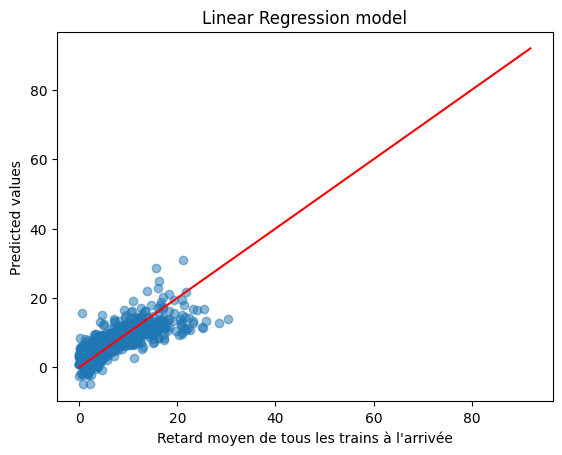

In [22]:
import matplotlib.pyplot as plt

#Compare the model to the actual values, if it is good then it should be close to match the diagonal line

plt.scatter(y_test, y_predict, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color = "red")
plt.xlabel("Retard moyen de tous les trains à l'arrivée")
plt.ylabel("Predicted values")
plt.title("Linear Regression model")
plt.show()

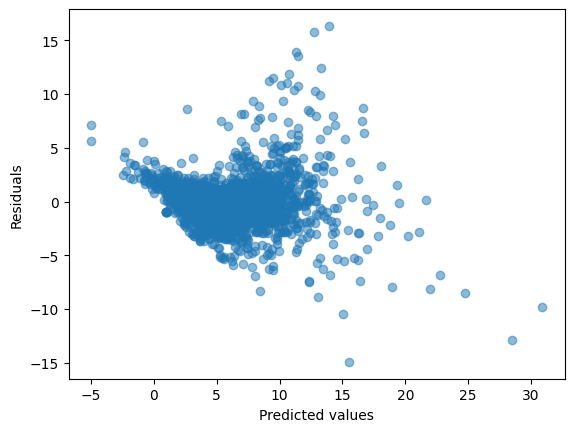

In [23]:
plt.scatter(y_predict, y_test - y_predict, alpha=0.5)
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.show()